
📊 Summary Statistics:
                       Date        GDP  Inflation
count                   24  24.000000  24.000000
mean   2011-07-02 18:00:00   1.786562   6.138533
min    2000-01-01 00:00:00   0.468396   3.328173
25%    2005-10-01 18:00:00   0.910291   3.991784
50%    2011-07-02 12:00:00   1.825345   5.390275
75%    2017-04-02 06:00:00   2.657319   7.111592
max    2023-01-01 00:00:00   3.567552  11.989390
std                    NaN   0.968397   2.531401


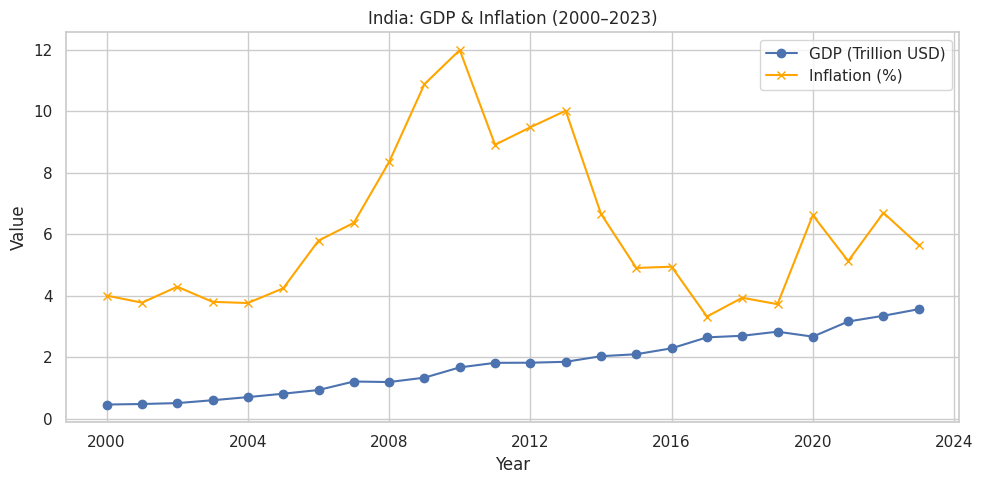


🧮 Normalized Values:
          Date  GDP_norm  Inflation_norm
23 2000-01-01  0.000000        0.078657
22 2001-01-01  0.005500        0.052085
21 2002-01-01  0.015018        0.111876
20 2003-01-01  0.044949        0.055152
19 2004-01-01  0.077685        0.050695

📅 Year-wise GDP Trend:
Year: 2000 → GDP: 0.47 Trillion USD
Year: 2001 → GDP: 0.49 Trillion USD
Year: 2002 → GDP: 0.51 Trillion USD
Year: 2003 → GDP: 0.61 Trillion USD
Year: 2004 → GDP: 0.71 Trillion USD
Year: 2005 → GDP: 0.82 Trillion USD
Year: 2006 → GDP: 0.94 Trillion USD
Year: 2007 → GDP: 1.22 Trillion USD
Year: 2008 → GDP: 1.20 Trillion USD
Year: 2009 → GDP: 1.34 Trillion USD
Year: 2010 → GDP: 1.68 Trillion USD
Year: 2011 → GDP: 1.82 Trillion USD
Year: 2012 → GDP: 1.83 Trillion USD
Year: 2013 → GDP: 1.86 Trillion USD
Year: 2014 → GDP: 2.04 Trillion USD
Year: 2015 → GDP: 2.10 Trillion USD
Year: 2016 → GDP: 2.29 Trillion USD
Year: 2017 → GDP: 2.65 Trillion USD
Year: 2018 → GDP: 2.70 Trillion USD
Year: 2019 → GDP: 2.84 Trilli

In [ ]:
# Install required libraries (run once)
!pip install wbdata pandas matplotlib seaborn --quiet

# Import necessary libraries
import wbdata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# Configure plots
%matplotlib inline
sns.set(style="whitegrid")

# Set up indicators and country
country = ["IND"]  # India
indicators = {
    "NY.GDP.MKTP.CD": "GDP (Current US$)",         # GDP
    "FP.CPI.TOTL.ZG": "Inflation (%)"              # Inflation
}

# Define date range
start_date = datetime(2000, 1, 1)
end_date = datetime(2023, 1, 1)

# Fetch data from World Bank
df = wbdata.get_dataframe(indicators, country, (start_date, end_date))

# Reset index and clean
df.reset_index(inplace=True)
df['date'] = pd.to_datetime(df['date'])  # convert date column
df.columns = ['Date', 'GDP', 'Inflation']  # Rename columns

# Drop missing rows and sort
df.dropna(inplace=True)
df['GDP'] = df['GDP'] / 1e12  # Convert GDP to Trillions
df.sort_values('Date', inplace=True)

# Summary statistics
print("\n📊 Summary Statistics:\n", df.describe())

# Plot GDP and Inflation
plt.figure(figsize=(10, 5))
plt.plot(df['Date'], df['GDP'], marker='o', label='GDP (Trillion USD)')
plt.plot(df['Date'], df['Inflation'], marker='x', label='Inflation (%)', color='orange')
plt.title("India: GDP & Inflation (2000–2023)")
plt.xlabel("Year")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# --- Function Recap ---
def normalize_column(series):
    return (series - series.min()) / (series.max() - series.min())

# Apply normalization
df['GDP_norm'] = normalize_column(df['GDP'])
df['Inflation_norm'] = normalize_column(df['Inflation'])

print("\n🧮 Normalized Values:\n", df[['Date', 'GDP_norm', 'Inflation_norm']].head())

# --- Loop Recap ---
print("\n📅 Year-wise GDP Trend:")
for index, row in df.iterrows():
    print(f"Year: {row['Date'].year} → GDP: {row['GDP']:.2f} Trillion USD")

# --- Class Recap ---
class EconomicIndicator:
    def __init__(self, year, gdp, inflation):
        self.year = year
        self.gdp = gdp
        self.inflation = inflation

    def summary(self):
        return f"Year {self.year}: GDP = {self.gdp:.2f} T USD, Inflation = {self.inflation:.2f}%"

# Show recent 3 years' summary using class
print("\n🧾 Recent Economic Summary:")
for _, row in df.tail(3).iterrows():
    obj = EconomicIndicator(row['Date'].year, row['GDP'], row['Inflation'])
    print(obj.summary())
